# Lab 2: Linear Systems and Matrix Multiplications

Ideas by Mike. Code by Claude. Text by both.

- Q1 & Q2: linear systems
- Q3: matrix-matrix multiplications and inverses

## Setup

Run the cell below as-is.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)

### Question 1: Balancing a chemical equation

The original roadside breathalyzers worked by a colour change. Orange potassium dichromate reacts with the ethanol in a person's breath and turns into green chromium sulfate. The unbalanced reaction is

$$
x_1\,\mathrm{K_2Cr_2O_7} + x_2\,\mathrm{C_2H_5OH} + x_3\,\mathrm{H_2SO_4}
\;\to\;
x_4\,\mathrm{Cr_2(SO_4)_3} + x_5\,\mathrm{CH_3COOH} + x_6\,\mathrm{K_2SO_4} + x_7\,\mathrm{H_2O}
$$


We wish to balance the reaction, i.e., find the (integers) $x_1,\ldots,x_7$.

**(a)** Write the balance equation for each element as a row of a matrix `A`, so that the equations are $A\mathbf{x} = 0$. Use the rows K, Cr, O, C, H, S and the columns $x_1, \dots, x_7$.

In [ ]:
# TODO
A.shape

**(b)** There are 7 unknowns but only 6 equations. Indeed, if $\mathbf{x}$ balances the reaction, so does $2\mathbf{x}$. We can arbitrarily set $x_1=1$ to address this. Add the equation $x_1 = 1$ as a new row to make a square system, then solve $A\mathbf{x} = 0$ with `np.linalg.solve`.

In [ ]:
# TODO
x

**(c)** Coefficients must be whole numbers. Multiply `x` by the smallest positive integer that makes every entry whole, and store the result in `x_whole`. The check below should print all zeros. Then write out the balanced equation.

In [ ]:
# TODO
print(x_whole)
print(A @ x_whole)

_Your answer here._

### Question 2: Piecewise polynomial interpolation

In calculus class last year, you were asked to draw functions meeting certain requirements. Today, we seek a function on $[0,3]$ that has:

- stationary points at $x=0$ and $x=2$
- a local maximum at $(1, 5)$
- an inflection point at $x = 2$
 
Take a moment to draw such a function.

_(Do this on paper)_

Today, instead of just drawing, we'll find an expression for a function like this. We'll stitch together three **cubics**, joined at $x = 0.5$ and $x = 1.5$:

- $f_1(x) = a_1x^3 + b_1x^2 + c_1x + d_1$ for $x \le 0.5$
- $f_2(x) = a_2(x-1)^3 + b_2(x-1)^2 + c_2(x-1) + d_2$ for $0.5 \le x \le 1.5$
- $f_3(x) = a_3(x-2)^3 + b_3(x-2)^2 + c_3(x-2) + d_3$ for $x \ge 1.5$

Notice that $f_2$ uses powers of $(x-1)$ and $f_3$ uses powers of $(x-2)$. These are still ordinary cubics, centred on the points we care about. It'll make the math cleaner.

We want our function to be $C^2$ smooth, meaning the function and its first and second derivatives are all continuous. 

**(a)** Find the first and second derivatives of $f_1$, $f_2$ and $f_3$. Then list every condition as an equation, such as $f_1'(0) = 0$. How many equations and how many unknowns do you have?

_(Do this on paper)_

**(b)** Some of your equations only involve one unknown, so they tell us its value right away. For example, $f_1'(0) = 0$ gives $c_1 = 0$. In that sense $c_1$ is no longer an "unknown" -- it is now known and we don't have to keep looking for it. How many actual unknowns are left?

_(Do this on paper)_

**(c)** Substitute the values from (b) into the remaining equations, then rearrange so the unknowns are on the left-hand side.

_(Do this on paper)_

**(d)** Write these equations as $Ax = b$, where $x = (a_1, b_1, d_1, a_2, b_2, a_3, d_3)$. (This can also serve as an answer-check to part (b), these are what I consider the "actual unknowns".) Create the `A` and `b` here in Python. What shape is your matrix $A$?

In [ ]:
# example
A = np.array([[1,2,3],[4,5,6]])
A

In [ ]:
# example
b = np.array([0,0,0,0])
b

**(e)** Hopefully your matrix isn't tall, which would mean we probably can't solve. If it is wide, add extra row(s) with whatever condition(s) make you happy so the matrix is square and we get 1 solution.

**(f)** Solve the linear system by running the cell below:

In [ ]:
x = np.linalg.solve(A, b)

**(g)** Run the cell below to plot your function. The dashed lines mark the joins, and the black dots mark the points to check. The curve should have no jumps or corners. Does it have the features labelled on the plot?

In [ ]:
def f(x, coeffs):
    a1, b1, d1, a2, b2, a3, d3 = coeffs
    return np.piecewise(x, [x <= 0.5, (x > 0.5) & (x <= 1.5), x > 1.5], [
        lambda x: a1 * x**3 + b1 * x**2 + d1,
        lambda x: a2 * (x - 1)**3 + b2 * (x - 1)**2 + 5,
        lambda x: a3 * (x - 2)**3 + d3,
    ])

xs = np.linspace(0, 3, 500)
plt.plot(xs, f(xs, x), linewidth=2)

labels = plt.gca().get_xaxis_transform()
for join in [0.5, 1.5]:
    plt.axvline(join, color="gray", linestyle="--", linewidth=1)
for mid, name in zip([0.25, 1, 2.25], ["$f_1$", "$f_2$", "$f_3$"]):
    plt.text(mid, 1.02, name, ha="center", transform=labels)

for point, label, offset in [(0, "stationary point?", (8, -24)),
                             (1, "local max?", (-28, 10)),
                             (2, "stationary and\ninflection point?", (8, 8))]:
    height = f(np.array([point], dtype=float), x)[0]
    plt.plot(point, height, "o", color="black")
    plt.annotate(f"({point}, {height:.3g})\n{label}", (point, height),
                 xytext=offset, textcoords="offset points")

plt.margins(y=0.25)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.show()

**(h)** Of all the conditions above, one is a bit special because it involves an inequality rather than an equality. Did it work out for you? Discuss.

_Your answer here._

### Question 3: Rotating a 3D point cloud

Below is a cloud of 1000 points in the shape of a letter F. `points` has shape `(3, 1000)`, so each **column** is one point $(x, y, z)$. The colours follow the points, so you can track where each part of the F goes.

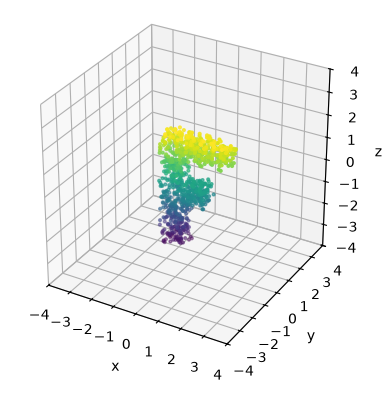

(3, 1000)

In [8]:
rng = np.random.default_rng(0)

def box(low, high, n):
    return rng.uniform(low, high, size=(n, 3))

points = np.vstack([box([0, 0, 0], [1, 1, 5], 550),
                    box([1, 0, 4], [3, 1, 5], 275),
                    box([1, 0, 2], [2, 1, 3], 175)]).T
points = points - points.mean(axis=1, keepdims=True)

def plot_clouds(*clouds, titles=None):
    fig = plt.figure(figsize=(4.5 * len(clouds), 4.5))
    for i, cloud in enumerate(clouds):
        ax = fig.add_subplot(1, len(clouds), i + 1, projection="3d")
        ax.scatter(*cloud, c=points[2], cmap="viridis", s=4)
        ax.set(xlim=(-4, 4), ylim=(-4, 4), zlim=(-4, 4), xlabel="x", ylabel="y", zlabel="z")
        ax.set_box_aspect((1, 1, 1))
        if titles:
            ax.set_title(titles[i])
    plt.show()

plot_clouds(points)
points.shape

These matrices rotate a point by an angle $\theta$ around the $z$-axis and around the $x$-axis:

$$
R_z = \begin{bmatrix} \cos\theta & -\sin\theta & 0 \\ \sin\theta & \cos\theta & 0 \\ 0 & 0 & 1 \end{bmatrix}
\qquad
R_x = \begin{bmatrix} 1 & 0 & 0 \\ 0 & \cos\theta & -\sin\theta \\ 0 & \sin\theta & \cos\theta \end{bmatrix}
$$

**(a)** Complete `rotate_z` and `rotate_x`, which take an angle in radians. Because each column of `points` is a point, `R @ points` rotates every point at once. Use this to rotate the cloud by 90 degrees around the $z$-axis, storing the result in `rotated_z`. `np.radians` converts degrees to radians.

In [ ]:
def rotate_z(theta):
    # TODO
    pass

def rotate_x(theta):
    # TODO
    pass

# TODO
plot_clouds(points, rotated_z, titles=["original", "rotated 90° around z"])

**(b)** Let `Rz = rotate_z(np.radians(90))` and `Rx = rotate_x(np.radians(90))`. Plot the cloud after rotating around $z$ first and then $x$, storing it in `z_then_x`, and after rotating around $x$ first and then $z$, storing it in `x_then_z`. Do you get the same result? What does this tell you about matrix multiplication?

In [ ]:
# TODO
plot_clouds(z_then_x, x_then_z, titles=["z, then x", "x, then z"])

_Your answer here._

**(c)** Now go backwards. Let `R = Rx @ Rz`. You are given `moved = R @ points`, and you want the original points back. This is a linear system, $Rp = \text{moved}$, and `np.linalg.solve` accepts a matrix on the right-hand side, solving for each column. Use it to compute `recovered`. Then compute `R.T @ moved` and compare the two. What does this tell you about the inverse of a rotation matrix?

In [ ]:
R = Rx @ Rz
moved = R @ points

# TODO
print(np.allclose(recovered, points))
plot_clouds(moved, recovered, titles=["moved", "recovered"])

_Your answer here._